<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/08_VAE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VAE: 分布を学ぶ潜在空間と生成 / VAE: Learning latent distributions and generating samples



エンコーダは平均と対数分散を出力します．$z=\mu+\exp(\frac12\log\sigma^2)\odot\epsilon$，$\epsilon\sim N(0,I)$．復元損失＋KL項で学習します．

The encoder outputs a mean and log variance. Use $z=\mu+\exp(\frac12\log\sigma^2)\odot\epsilon$, with $\epsilon\sim N(0,I)$. Train with reconstruction loss plus a KL term.

8×8の画素を[0,1]として扱う簡易Bernoulli観測モデルです．表示用の画像はdecoderの平均値であり，画素ごとのBernoulli再サンプルは行いません．

This uses a simplified Bernoulli observation model for 8×8 pixel values in [0,1]. Displayed images are decoder means; individual pixels are not resampled from Bernoulli distributions.


## 準備 / Setup


In [ ]:
import sys, subprocess, importlib.util
# Colabの既存PyTorchを優先し，不足パッケージだけ追加します． / Reuse Colab packages; install only missing dependencies.
for module, package in [('torch','torch'), ('sklearn','scikit-learn'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import random, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import ipywidgets as widgets
from IPython.display import display, clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('PyTorch:', torch.__version__, '| 実行機器 / Device:', device)


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


PyTorch: 2.14.1+cu130 | 実行機器 / Device: cuda


## 設定 / Configuration


In [ ]:
BATCH_SIZE=128
LATENT_DIM=2
EPOCHS=65
BETA=1.0
LEARNING_RATE=.002


## データ / Data


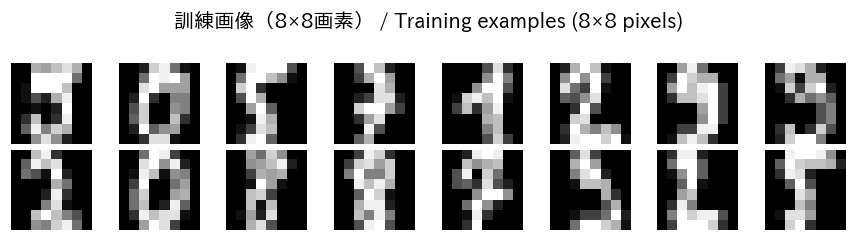

訓練数 / Train: 1437 | 評価数 / Held-out: 360


In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
raw = load_digits()
# sklearn同梱の8×8手書き数字．通信・認証は不要です． / Use the bundled sklearn 8×8 digits; no dataset download or authentication.
# 画像モデルの学習にクラスラベルは使いません．可視化だけに使います． / Class labels are used for visualization, not image-model training.
images = (raw.data / 16.0).astype('float32')
train_idx, test_idx = train_test_split(np.arange(len(images)), test_size=0.2,
                                    random_state=SEED, stratify=raw.target)
x_train = torch.tensor(images[train_idx])
x_test = torch.tensor(images[test_idx])
y_test = raw.target[test_idx]
loader = DataLoader(TensorDataset(x_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
def image_grid(x, title='', nrow=8):
    x = torch.as_tensor(x).detach().cpu().reshape(-1,8,8).numpy()
    rows = math.ceil(len(x)/nrow)
    fig, ax = plt.subplots(rows,nrow,figsize=(nrow,rows*1.1),squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a,im in zip(ax.ravel(),x): a.imshow(im,cmap='gray',vmin=0,vmax=1)
    fig.suptitle(title); plt.tight_layout(); plt.show()
image_grid(x_train[:16], '訓練画像（8×8画素） / Training examples (8×8 pixels)')
print('訓練数 / Train:',len(x_train),'| 評価数 / Held-out:',len(x_test))


## モデル / Model


In [ ]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__();self.enc=nn.Sequential(nn.Linear(64,128),nn.ReLU(),nn.Linear(128,64),nn.ReLU())
        self.mean=nn.Linear(64,LATENT_DIM);self.logvar=nn.Linear(64,LATENT_DIM)
        self.dec=nn.Sequential(nn.Linear(LATENT_DIM,64),nn.ReLU(),nn.Linear(64,128),nn.ReLU(),nn.Linear(128,64))
    def encode(self,x):
        h=self.enc(x);return self.mean(h),self.logvar(h).clamp(-12,12)
    def decode(self,z):return torch.sigmoid(self.dec(z))
    def forward(self,x):
        mu,lv=self.encode(x);eps=torch.randn_like(mu);z=mu+torch.exp(.5*lv)*eps
        return self.dec(z),mu,lv
def vae_loss(logits,x,mu,lv):
    rec=F.binary_cross_entropy_with_logits(logits,x,reduction='none').sum(1).mean()
    kl=-.5*(1+lv-mu.square()-lv.exp()).sum(1).mean()
    return rec+BETA*kl,rec,kl
model=VAE().to(device);optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)


## 学習 / Training


エポック / Epoch 1: 合計 / total=40.43, 再構成 / rec=40.38, KL=0.04
エポック / Epoch 15: 合計 / total=27.17, 再構成 / rec=27.14, KL=0.03
エポック / Epoch 30: 合計 / total=26.68, 再構成 / rec=26.04, KL=0.64
エポック / Epoch 45: 合計 / total=26.10, 再構成 / rec=24.99, KL=1.12
エポック / Epoch 60: 合計 / total=25.04, 再構成 / rec=23.05, KL=1.98


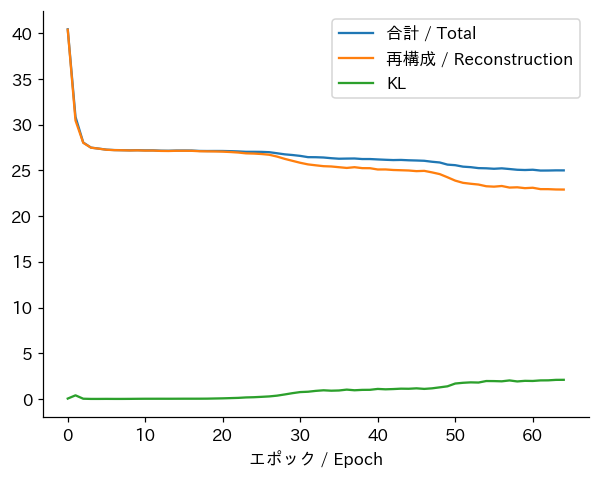

In [ ]:
history=[]
for epoch in range(EPOCHS):
    model.train();s=np.zeros(3)
    for (xb,) in loader:
        xb=xb.to(device);optimizer.zero_grad();logits,mu,lv=model(xb)
        loss,rec,kl=vae_loss(logits,xb,mu,lv);loss.backward();optimizer.step()
        s+=np.array([loss.item(),rec.item(),kl.item()])*len(xb)
    history.append(s/len(x_train))
    if epoch==0 or (epoch+1)%15==0:print(f'エポック / Epoch {epoch+1}: 合計 / total={history[-1][0]:.2f}, 再構成 / rec={history[-1][1]:.2f}, KL={history[-1][2]:.2f}')
plt.plot(history);plt.legend(['合計 / Total','再構成 / Reconstruction','KL']);plt.xlabel('エポック / Epoch');plt.show()


## 評価と可視化 / Evaluation and visualization


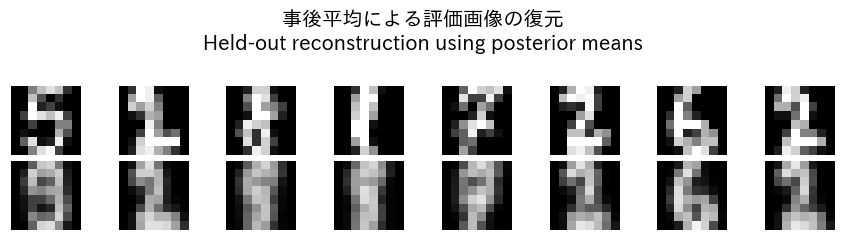

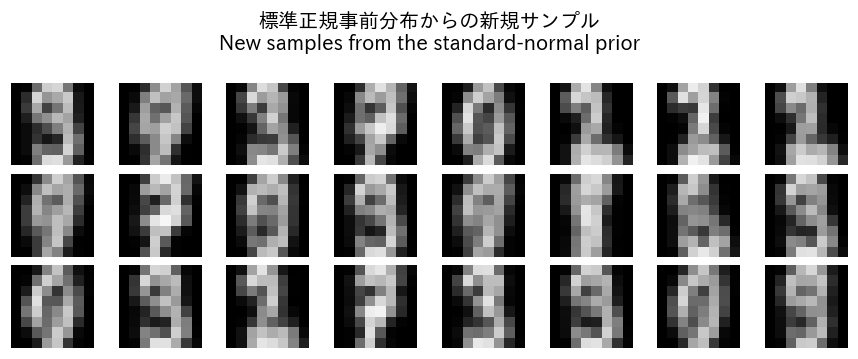

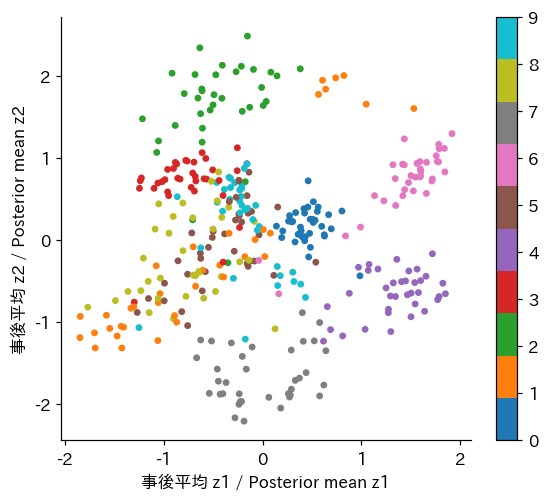

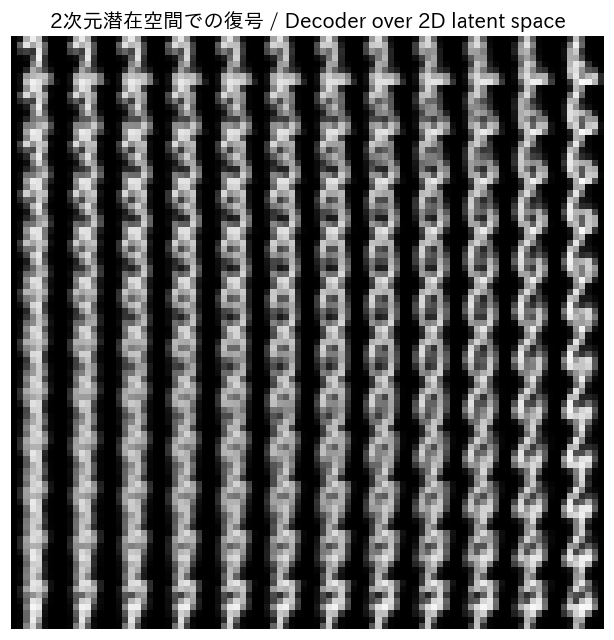

In [ ]:
model.eval()
with torch.no_grad():
    mu,lv=model.encode(x_test.to(device));recon=model.decode(mu).cpu()
    sampled=model.decode(torch.randn(24,LATENT_DIM,device=device)).cpu()
image_grid(torch.cat([x_test[:8],recon[:8]]),'事後平均による評価画像の復元\nHeld-out reconstruction using posterior means')
image_grid(sampled,'標準正規事前分布からの新規サンプル\nNew samples from the standard-normal prior')
z=mu.cpu().numpy()
plt.figure(figsize=(6,5));plt.scatter(z[:,0],z[:,1],c=y_test,cmap='tab10',s=12);plt.colorbar(ticks=range(10));plt.xlabel('事後平均 z1 / Posterior mean z1');plt.ylabel('事後平均 z2 / Posterior mean z2');plt.show()
from scipy.stats import norm
values=norm.ppf(np.linspace(.03,.97,12)).astype('float32')
grid=np.array([[a,b] for b in values[::-1] for a in values],dtype='float32')
with torch.no_grad():canvas=model.decode(torch.tensor(grid,device=device)).cpu().reshape(12,12,8,8).permute(0,2,1,3).reshape(96,96)
plt.figure(figsize=(7,7));plt.imshow(canvas,cmap='gray',vmin=0,vmax=1);plt.title('2次元潜在空間での復号 / Decoder over 2D latent space');plt.axis('off');plt.show()


## インタラクティブ操作 / Interactive controls


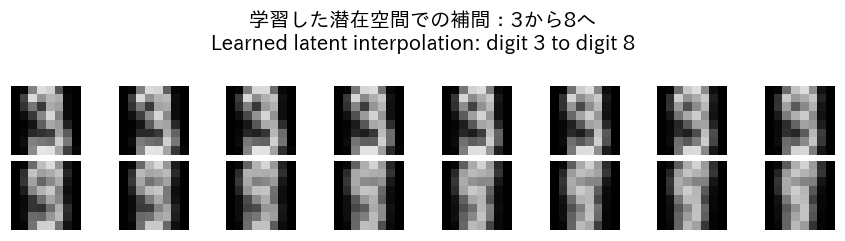

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='t', max=1.0, step=0.02), Ou…

<function __main__.show_interpolation(t=0.5)>

In [ ]:
# 実際に学習したdecoderで補間します．画像同士のクロスフェードではありません． / Interpolate through the learned decoder rather than crossfading images.
a=int(np.flatnonzero(y_test==3)[0]);b=int(np.flatnonzero(y_test==8)[0])
za=mu[a:a+1];zb=mu[b:b+1]
with torch.no_grad():
    t=torch.linspace(0,1,16,device=device)[:,None]
    path=(1-t)*za+t*zb;interpolated=model.decode(path).cpu()
image_grid(interpolated,'学習した潜在空間での補間：3から8へ\nLearned latent interpolation: digit 3 to digit 8',nrow=8)
def show_interpolation(t=.5):
    with torch.no_grad():im=model.decode((1-t)*za+t*zb).cpu().reshape(8,8)
    fig,ax=plt.subplots(1,2,figsize=(6,2.7))
    ax[0].scatter(z[:,0],z[:,1],c='lightgray',s=5)
    p=((1-t)*za+t*zb).cpu().numpy()[0];endpoints=torch.cat([za,zb]).cpu().numpy()
    ax[0].plot(endpoints[:,0],endpoints[:,1],color='gray');ax[0].scatter(*p,color='darkorange');ax[0].set_title('潜在位置 / Latent location')
    ax[1].imshow(im,cmap='gray',vmin=0,vmax=1);ax[1].axis('off');ax[1].set_title(f'復号結果 / Decoded t={t:.2f}');plt.tight_layout();plt.show()
widgets.interact(show_interpolation,t=widgets.FloatSlider(min=0,max=1,step=.02,value=.5,continuous_update=False))


## 観察・変更 / Observe and modify
BETAを0，0.1，1，4に変えて再学習し，復元と事前分布からのサンプルを比較します．強い正則化は常に高品質な生成につながるわけではありません．この2次元の小型モデルでは，3→8の変化が完全に滑らかになることも保証されません．潜在次元を変える場合，2DグリッドのセルはLATENT_DIM=2専用です．

Retrain with BETA = 0, 0.1, 1, and 4; compare reconstructions and prior samples. Stronger regularization does not always improve generation. This small 2D model does not guarantee a perfectly smooth 3-to-8 transition. The 2D grid cell requires LATENT_DIM = 2.


## 参考 / References
- [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114)
